In [1]:
import pandas as pd

path = r"D:\APCIRA\data\cleaned_network_data\cleaned_network_data.csv"

df = pd.read_csv(path)

print(df.shape)
print(df.head())

(95473, 26)
      label  dst_port  flow_duration  total_fwd_packets  total_bwd_packets  \
0    BENIGN      80.0       452460.0                8.0               11.0   
1      DDoS      80.0      9365755.0                4.0                0.0   
2    BENIGN   56026.0           58.0                1.0                1.0   
3  DoS Hulk      80.0     99971800.0                6.0                6.0   
4    BENIGN     443.0      1840298.0                3.0                3.0   

   total_len_fwd  total_len_bwd  flow_packets_s  fwd_packets_s  bwd_packets_s  \
0         1763.0        12834.0       41.992662      17.681121      24.311541   
1           24.0            0.0        0.427088       0.427088       0.000000   
2            0.0            0.0    34482.758620   17241.379310   17241.379310   
3          350.0        11595.0        0.120034       0.060017       0.060017   
4            0.0            0.0        3.260342       1.630171       1.630171   

   ...  syn_flag_count  ack_flag

In [2]:
X = df.drop(columns=["label"])
y = df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (95473, 25)
y shape: (95473,)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (76378, 25)
X_test : (19095, 25)
y_train: (76378,)
y_test : (19095,)


In [4]:
print("Training classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

Training classes:
label
BENIGN              41861
DoS Hulk             6277
DDoS                 6198
PortScan             6114
DoS GoldenEye        4189
FTP-Patator          3407
SSH-Patator          2519
DoS Slowhttptest     2116
DoS slowloris        2110
Bot                  1549
Infiltration           29
Heartbleed              9
Name: count, dtype: int64

Testing classes:
label
BENIGN              10465
DoS Hulk             1570
DDoS                 1550
PortScan             1529
DoS GoldenEye        1047
FTP-Patator           852
SSH-Patator           630
DoS Slowhttptest      529
DoS slowloris         527
Bot                   387
Infiltration            7
Heartbleed              2
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation ready!")

5-Fold Stratified Cross-Validation ready!


In [6]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created!")

Random Forest model created!


In [7]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring="f1_macro",
    n_jobs=-1
)

print("F1 Macro for each fold:")
print(cv_scores)

print("\nMean F1 Macro:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

F1 Macro for each fold:
[0.97852627 0.97941761 0.95963346 0.99446663 0.96080405]

Mean F1 Macro: 0.9745696048814555
Standard Deviation: 0.013020204668051686


In [8]:
model.fit(X_train, y_train)

print("Final model trained!")

Final model trained!


In [9]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 19095


In [10]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
weighted_f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy :", accuracy)
print("Macro F1 :", macro_f1)
print("Weighted F1:", weighted_f1)

Accuracy : 0.9972244042943179
Macro F1 : 0.9951060635286643
Weighted F1: 0.9972302617528541


In [11]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                  precision    recall  f1-score   support

          BENIGN       1.00      1.00      1.00     10465
             Bot       0.97      0.99      0.98       387
            DDoS       1.00      1.00      1.00      1550
   DoS GoldenEye       1.00      1.00      1.00      1047
        DoS Hulk       1.00      1.00      1.00      1570
DoS Slowhttptest       0.98      0.99      0.98       529
   DoS slowloris       0.99      0.99      0.99       527
     FTP-Patator       1.00      1.00      1.00       852
      Heartbleed       1.00      1.00      1.00         2
    Infiltration       1.00      1.00      1.00         7
        PortScan       1.00      1.00      1.00      1529
     SSH-Patator       1.00      1.00      1.00       630

        accuracy                           1.00     19095
       macro avg       0.99      1.00      1.00     19095
    weighted avg       1.00      1.00      1.00     19095



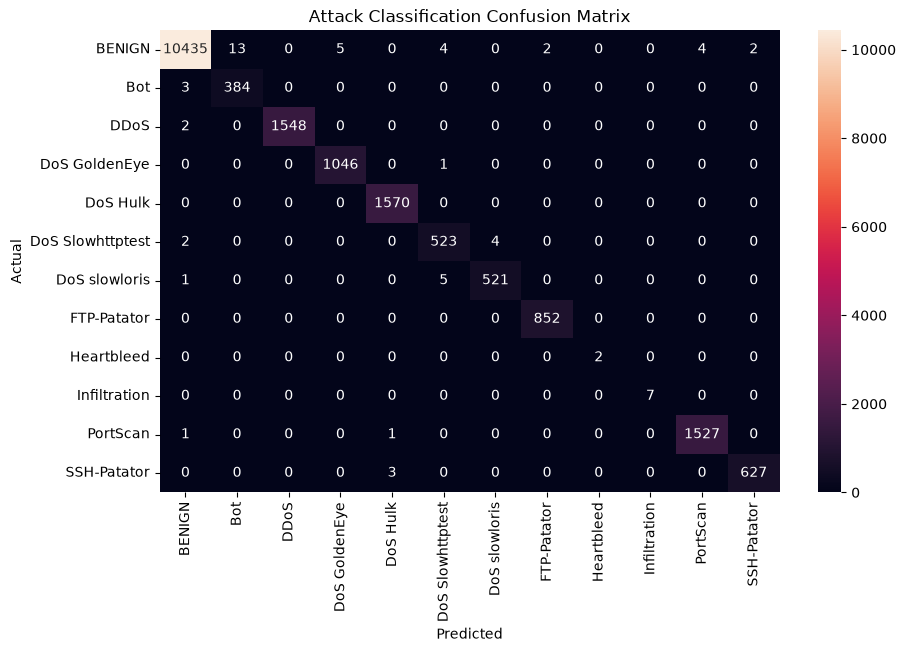

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(10, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Attack Classification Confusion Matrix")
plt.show()

In [13]:
import pandas as pd

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

dst_port                   0.118320
bwd_packet_length_mean     0.078863
total_len_bwd              0.062250
total_bwd_packets          0.061041
total_len_fwd              0.058391
init_win_bytes_forward     0.054599
max_packet_length          0.053207
packet_length_mean         0.052663
bwd_packets_s              0.052110
fwd_packet_length_mean     0.049744
flow_packets_s             0.048845
total_fwd_packets          0.045977
init_win_bytes_backward    0.045834
flow_duration              0.043436
packet_length_std          0.040232
fwd_packets_s              0.040171
active_mean                0.020135
idle_mean                  0.018826
psh_flag_count             0.017252
min_packet_length          0.017204
ack_flag_count             0.012867
down_up_ratio              0.003752
syn_flag_count             0.003537
fin_flag_count             0.000743
rst_flag_count             0.000000
dtype: float64


In [14]:
X_train_no_port = X_train.drop(columns=["dst_port"])
X_test_no_port = X_test.drop(columns=["dst_port"])

print("Features with dst_port   :", X_train.shape[1])
print("Features without dst_port:", X_train_no_port.shape[1])

Features with dst_port   : 25
Features without dst_port: 24


In [15]:
model_no_port = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_no_port.fit(X_train_no_port, y_train)

print("Model without dst_port trained!")

Model without dst_port trained!


In [16]:
y_pred_no_port = model_no_port.predict(X_test_no_port)

accuracy_no_port = accuracy_score(y_test, y_pred_no_port)
macro_f1_no_port = f1_score(y_test, y_pred_no_port, average="macro")
weighted_f1_no_port = f1_score(y_test, y_pred_no_port, average="weighted")

print("Accuracy :", accuracy_no_port)
print("Macro F1 :", macro_f1_no_port)
print("Weighted F1:", weighted_f1_no_port)

Accuracy : 0.9956009426551453
Macro F1 : 0.9926470931987964
Weighted F1: 0.9956272030991902


In [18]:
import joblib

model_path = r"D:\APCIRA\ml\models\attack_classifier.pkl"

joblib.dump(model_no_port, model_path)

print("Model saved successfully!")
print("Path:", model_path)

Model saved successfully!
Path: D:\APCIRA\ml\models\attack_classifier.pkl


In [19]:
import joblib

model_path = r"D:\APCIRA\ml\models\attack_classifier.pkl"

model = joblib.load(model_path)

print("Model loaded!")

Model loaded!


In [20]:
print(model.feature_names_in_)

['flow_duration' 'total_fwd_packets' 'total_bwd_packets' 'total_len_fwd'
 'total_len_bwd' 'flow_packets_s' 'fwd_packets_s' 'bwd_packets_s'
 'fwd_packet_length_mean' 'bwd_packet_length_mean' 'min_packet_length'
 'max_packet_length' 'packet_length_mean' 'packet_length_std'
 'syn_flag_count' 'ack_flag_count' 'rst_flag_count' 'psh_flag_count'
 'fin_flag_count' 'down_up_ratio' 'init_win_bytes_forward'
 'init_win_bytes_backward' 'active_mean' 'idle_mean']


In [21]:
import pandas as pd

custom_data = pd.DataFrame([{
    "flow_duration": 452460.0,
    "total_fwd_packets": 8.0,
    "total_bwd_packets": 11.0,
    "total_len_fwd": 1763.0,
    "total_len_bwd": 12834.0,
    "flow_packets_s": 41.992662,
    "fwd_packets_s": 17.681121,
    "bwd_packets_s": 24.311541,
    "fwd_packet_length_mean": 220.375,
    "bwd_packet_length_mean": 1166.727273,
    "min_packet_length": 0.0,
    "max_packet_length": 1514.0,
    "packet_length_mean": 628.5,
    "packet_length_std": 500.0,
    "syn_flag_count": 0.0,
    "ack_flag_count": 0.0,
    "rst_flag_count": 0.0,
    "psh_flag_count": 1.0,
    "fin_flag_count": 0.0,
    "down_up_ratio": 1.0,
    "init_win_bytes_forward": 8192.0,
    "init_win_bytes_backward": 1095.0,
    "active_mean": 0.0,
    "idle_mean": 0.0
}])

prediction = model.predict(custom_data)

print("Predicted Attack:", prediction[0])

Predicted Attack: BENIGN


In [22]:
probabilities = model.predict_proba(custom_data)[0]

results = pd.DataFrame({
    "Attack": model.classes_,
    "Probability": probabilities
}).sort_values("Probability", ascending=False)

print(results)

              Attack  Probability
0             BENIGN          1.0
1                Bot          0.0
2               DDoS          0.0
3      DoS GoldenEye          0.0
4           DoS Hulk          0.0
5   DoS Slowhttptest          0.0
6      DoS slowloris          0.0
7        FTP-Patator          0.0
8         Heartbleed          0.0
9       Infiltration          0.0
10          PortScan          0.0
11       SSH-Patator          0.0


In [24]:
# Get one real DDoS sample
sample = df[df["label"] == "DDoS"].drop(columns=["label", "dst_port"]).iloc[[0]]

# Predict
prediction = model.predict(sample)

print("Actual Attack   :", "DDoS")
print("Predicted Attack:", prediction[0])

Actual Attack   : DDoS
Predicted Attack: DDoS


In [25]:
probabilities = model.predict_proba(sample)[0]

results = pd.DataFrame({
    "Attack": model.classes_,
    "Probability": probabilities
}).sort_values("Probability", ascending=False)

print(results)

              Attack  Probability
2               DDoS          1.0
0             BENIGN          0.0
1                Bot          0.0
3      DoS GoldenEye          0.0
4           DoS Hulk          0.0
5   DoS Slowhttptest          0.0
6      DoS slowloris          0.0
7        FTP-Patator          0.0
8         Heartbleed          0.0
9       Infiltration          0.0
10          PortScan          0.0
11       SSH-Patator          0.0


In [26]:
import pandas as pd

path = r"D:\APCIRA\MachineLearningCVE\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"

portscan_df = pd.read_csv(path)

print("Shape:", portscan_df.shape)
print(portscan_df.head())

Shape: (286467, 79)
    Destination Port   Flow Duration   Total Fwd Packets  \
0                 22         1266342                  41   
1                 22         1319353                  41   
2                 22             160                   1   
3                 22         1303488                  41   
4              35396              77                   1   

    Total Backward Packets  Total Length of Fwd Packets  \
0                       44                         2664   
1                       44                         2664   
2                        1                            0   
3                       42                         2728   
4                        2                            0   

    Total Length of Bwd Packets   Fwd Packet Length Max  \
0                          6954                     456   
1                          6954                     456   
2                             0                       0   
3                          6

In [27]:
print(portscan_df.columns.tolist())

[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag 

In [28]:
feature_mapping = {
    "dst_port": " Destination Port",
    "flow_duration": " Flow Duration",
    "total_fwd_packets": " Total Fwd Packets",
    "total_bwd_packets": " Total Backward Packets",
    "total_len_fwd": "Total Length of Fwd Packets",
    "total_len_bwd": " Total Length of Bwd Packets",
    "flow_packets_s": " Flow Packets/s",
    "fwd_packets_s": "Fwd Packets/s",
    "bwd_packets_s": " Bwd Packets/s",
    "fwd_packet_length_mean": " Fwd Packet Length Mean",
    "bwd_packet_length_mean": " Bwd Packet Length Mean",
    "min_packet_length": " Min Packet Length",
    "max_packet_length": " Max Packet Length",
    "packet_length_mean": " Packet Length Mean",
    "packet_length_std": " Packet Length Std",
    "syn_flag_count": " SYN Flag Count",
    "ack_flag_count": " ACK Flag Count",
    "rst_flag_count": " RST Flag Count",
    "psh_flag_count": " PSH Flag Count",
    "fin_flag_count": "FIN Flag Count",
    "down_up_ratio": " Down/Up Ratio",
    "init_win_bytes_forward": "Init_Win_bytes_forward",
    "init_win_bytes_backward": " Init_Win_bytes_backward",
    "active_mean": "Active Mean",
    "idle_mean": "Idle Mean"
}

portscan_features = portscan_df[
    list(feature_mapping.values())
].copy()

portscan_features.columns = list(feature_mapping.keys())

print(portscan_features.shape)
print(portscan_features.columns.tolist())

(286467, 25)
['dst_port', 'flow_duration', 'total_fwd_packets', 'total_bwd_packets', 'total_len_fwd', 'total_len_bwd', 'flow_packets_s', 'fwd_packets_s', 'bwd_packets_s', 'fwd_packet_length_mean', 'bwd_packet_length_mean', 'min_packet_length', 'max_packet_length', 'packet_length_mean', 'packet_length_std', 'syn_flag_count', 'ack_flag_count', 'rst_flag_count', 'psh_flag_count', 'fin_flag_count', 'down_up_ratio', 'init_win_bytes_forward', 'init_win_bytes_backward', 'active_mean', 'idle_mean']


In [29]:
# Remove dst_port to match the final model
portscan_X = portscan_features.drop(columns=["dst_port"])

# Select 5 random real samples
random_samples = portscan_X.sample(
    n=5,
    random_state=42
)

# Predict
predictions = model.predict(random_samples)

for i, prediction in enumerate(predictions):
    print(f"Sample {i+1}: {prediction}")

Sample 1: BENIGN
Sample 2: BENIGN
Sample 3: PortScan
Sample 4: BENIGN
Sample 5: PortScan


In [30]:
# Check the label distribution in the original file
print(portscan_df[" Label"].value_counts())

 Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64


In [31]:
# Get only genuine PortScan rows
portscan_only = portscan_df[
    portscan_df[" Label"].str.strip() == "PortScan"
]

# Select 10 random PortScan flows
sample_indices = portscan_only.sample(
    n=10,
    random_state=42
).index

# Get their 24 model features
test_samples = portscan_features.loc[sample_indices].drop(
    columns=["dst_port"]
)

# Predict
predictions = model.predict(test_samples)

# Display results
for i, prediction in enumerate(predictions):
    print(f"Sample {i+1}: Actual = PortScan | Predicted = {prediction}")

Sample 1: Actual = PortScan | Predicted = PortScan
Sample 2: Actual = PortScan | Predicted = PortScan
Sample 3: Actual = PortScan | Predicted = PortScan
Sample 4: Actual = PortScan | Predicted = PortScan
Sample 5: Actual = PortScan | Predicted = PortScan
Sample 6: Actual = PortScan | Predicted = PortScan
Sample 7: Actual = PortScan | Predicted = PortScan
Sample 8: Actual = PortScan | Predicted = PortScan
Sample 9: Actual = PortScan | Predicted = PortScan
Sample 10: Actual = PortScan | Predicted = PortScan


In [32]:
# Get 5 random genuine PortScan rows
sample = portscan_df[
    portscan_df[" Label"].str.strip() == "PortScan"
].sample(n=5, random_state=100)

# Get the corresponding 25 features
sample_features = portscan_features.loc[sample.index]

# Remove dst_port because our final model does not use it
sample_features = sample_features.drop(columns=["dst_port"])

# Display all 24 features clearly
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print(sample_features.to_string(index=False))

 flow_duration  total_fwd_packets  total_bwd_packets  total_len_fwd  total_len_bwd  flow_packets_s  fwd_packets_s  bwd_packets_s  fwd_packet_length_mean  bwd_packet_length_mean  min_packet_length  max_packet_length  packet_length_mean  packet_length_std  syn_flag_count  ack_flag_count  rst_flag_count  psh_flag_count  fin_flag_count  down_up_ratio  init_win_bytes_forward  init_win_bytes_backward  active_mean  idle_mean
            46                  1                  1              2              6     43478.26087    21739.13043    21739.13043                     2.0                     6.0                  2                  6            3.333333           2.309401               0               0               0               1               0              1                    1024                        0          0.0        0.0
            42                  1                  1              0              6     47619.04762    23809.52381    23809.52381                     0.0    

In [45]:
for i, (_, row) in enumerate(sample_features.iterrows(), 1):
    print(f"\n========== PORTSCAN SAMPLE {i} ==========")
    for feature, value in row.items():
        print(f'"{feature}": {value},')


========== PORTSCAN SAMPLE 1 ==========
"flow_duration": 46.0,
"total_fwd_packets": 1.0,
"total_bwd_packets": 1.0,
"total_len_fwd": 2.0,
"total_len_bwd": 6.0,
"flow_packets_s": 43478.26087,
"fwd_packets_s": 21739.13043,
"bwd_packets_s": 21739.13043,
"fwd_packet_length_mean": 2.0,
"bwd_packet_length_mean": 6.0,
"min_packet_length": 2.0,
"max_packet_length": 6.0,
"packet_length_mean": 3.333333333,
"packet_length_std": 2.309401077,
"syn_flag_count": 0.0,
"ack_flag_count": 0.0,
"rst_flag_count": 0.0,
"psh_flag_count": 1.0,
"fin_flag_count": 0.0,
"down_up_ratio": 1.0,
"init_win_bytes_forward": 1024.0,
"init_win_bytes_backward": 0.0,
"active_mean": 0.0,
"idle_mean": 0.0,

========== PORTSCAN SAMPLE 2 ==========
"flow_duration": 42.0,
"total_fwd_packets": 1.0,
"total_bwd_packets": 1.0,
"total_len_fwd": 0.0,
"total_len_bwd": 6.0,
"flow_packets_s": 47619.04762,
"fwd_packets_s": 23809.52381,
"bwd_packets_s": 23809.52381,
"fwd_packet_length_mean": 0.0,
"bwd_packet_length_mean": 6.0,
"min_packet_

In [43]:
prediction = model.predict(custom_data)
print("Predicted Attack:", prediction[0])

Predicted Attack: BENIGN
